In [1]:
# 第一部分：导入必要的库（电脑B）
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


[WARNING] ME(35972:38656,MainProcess):2026-10-06-21:12:26.975.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(35972:38656,MainProcess):2026-10-06-21:12:26.976.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（电脑B - 自编码器降维 + 测量后权重实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1                # 数据采样比例
TEST_SIZE = 0.2                 # 测试集比例
BATCH_SIZE = 32                 # 批处理大小

# 降维方法改为自编码器
DIM_REDUCTION_METHOD = 'autoencoder'   # 固定降维方法

# 自编码器训练参数（与实验三基线一致）
PCA_COMPONENTS = 8              # 降维目标维度（与量子比特数一致）
AUTOENCODER_EPOCHS = 50         # 自编码器训练轮数
AUTOENCODER_LR = 0.001          # 自编码器学习率
AUTOENCODER_HIDDEN_DIMS = [256, 64]  # 编码器隐藏层维度（输入784 -> 256 -> 64 -> 8）

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                # 固定层数

# 测量后权重类型
WEIGHT_TYPES = ['scalar', 'diagonal', 'full']  # 三种权重类型

# 训练参数
NUM_EPOCHS = 150                # 训练轮数
LEARNING_RATE = 0.01            # 学习率
PARALLEL_WORKER = 2             # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE      # 运行模式
MS_DEVICE = "CPU"               # 设备目标
SEED = 42                       # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)


[WARNING] ME(35972:38656,MainProcess):2026-10-06-21:12:31.467.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：自编码器降维和数据预处理函数（电脑B，与实验三基线一致）
# ============================================

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import mindspore.dataset as ds
import mindspore as ms
from mindspore import nn, ops, Tensor
from mindspore.common.initializer import HeNormal

class Autoencoder(nn.Cell):
    """自编码器模型，用于降维（与实验三基线一致：784 -> 256 -> 64 -> 8）"""
    def __init__(self, input_dim=784, hidden_dims=[256, 64], latent_dim=8):
        super(Autoencoder, self).__init__()
        # 编码器
        encoder_layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers.append(nn.Dense(prev_dim, h_dim, weight_init=HeNormal()))
            encoder_layers.append(nn.ReLU())
            prev_dim = h_dim
        encoder_layers.append(nn.Dense(prev_dim, latent_dim, weight_init=HeNormal()))
        self.encoder = nn.SequentialCell(encoder_layers)

        # 解码器
        decoder_layers = []
        prev_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers.append(nn.Dense(prev_dim, h_dim, weight_init=HeNormal()))
            decoder_layers.append(nn.ReLU())
            prev_dim = h_dim
        decoder_layers.append(nn.Dense(prev_dim, input_dim, weight_init=HeNormal()))
        self.decoder = nn.SequentialCell(decoder_layers)

    def construct(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

def load_mnist_data():
    """加载MNIST数据集（与原代码相同）"""
    import os
    from torchvision.datasets import MNIST

    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)

    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)

    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels

    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)

    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images),
        int(len(all_images) * SAMPLE_RATIO),
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]

    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")

    return sampled_images, sampled_labels

def train_autoencoder(train_images, epochs=50, lr=0.001, batch_size=128):
    """训练自编码器，返回编码器和用于自编码器输入的scaler"""
    scaler_for_ae = MinMaxScaler(feature_range=(0, 1))
    train_images_scaled = scaler_for_ae.fit_transform(train_images)

    train_dataset = ds.NumpySlicesDataset(train_images_scaled, column_names=["image"], shuffle=True).batch(batch_size)

    autoencoder = Autoencoder(input_dim=train_images.shape[1],
                              hidden_dims=AUTOENCODER_HIDDEN_DIMS,
                              latent_dim=PCA_COMPONENTS)
    loss_fn = nn.MSELoss()
    optimizer = nn.Adam(autoencoder.trainable_params(), learning_rate=lr)

    def forward_fn(data):
        encoded, decoded = autoencoder(data)
        loss = loss_fn(decoded, data)
        return loss

    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters)

    print("开始训练自编码器...")
    for epoch in range(epochs):
        total_loss = 0
        step = 0
        for data in train_dataset.create_tuple_iterator():
            data = data[0]
            loss, grads = grad_fn(data)
            optimizer(grads)
            total_loss += loss.asnumpy()
            step += 1
        avg_loss = total_loss / step
        if (epoch+1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.6f}")

    return autoencoder.encoder, scaler_for_ae

def preprocess_data_autoencoder(images, labels, encoder=None, scaler_for_ae=None, final_scaler=None, is_train=True):
    """
    自编码器降维预处理函数
    返回: (dataset, final_scaler, encoder, scaler_for_ae)
    """
    if is_train:
        encoder, scaler_for_ae = train_autoencoder(images, epochs=AUTOENCODER_EPOCHS,
                                                    lr=AUTOENCODER_LR, batch_size=128)
        images_scaled = scaler_for_ae.transform(images)
        images_tensor = Tensor(images_scaled, ms.float32)
        latent_features = encoder(images_tensor).asnumpy()
        print(f"自编码器降维完成，输出形状: {latent_features.shape}")

        final_scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = final_scaler.fit_transform(latent_features)
    else:
        images_scaled = scaler_for_ae.transform(images)
        images_tensor = Tensor(images_scaled, ms.float32)
        latent_features = encoder(images_tensor).asnumpy()
        normalized_data = final_scaler.transform(latent_features)

    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)

    return dataset, final_scaler, encoder, scaler_for_ae


In [4]:
# 第四部分：量子电路构建函数（通用）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（固定使用此结构）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（修改后：测量后权重）
# ============================================

class LearnableWeight(nn.Cell):
    """测量后可学习的权重层（对量子测量输出进行线性变换）"""
    def __init__(self, input_dim=NUM_QUBITS, weight_type="diagonal"):
        super(LearnableWeight, self).__init__()
        self.weight_type = weight_type
        self.input_dim = input_dim

        if weight_type == "scalar":
            self.weight = ms.Parameter(Tensor(np.ones(1) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(1), dtype=ms.float32))
            print(f"  权重类型: 标量权重 (1个权重参数)")

        elif weight_type == "diagonal":
            self.weight = ms.Parameter(Tensor(np.ones(input_dim) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(input_dim), dtype=ms.float32))
            print(f"  权重类型: 对角权重 ({input_dim}个权重参数)")

        elif weight_type == "full":
            self.linear = nn.Dense(input_dim, input_dim, has_bias=True)
            print(f"  权重类型: 全连接权重 ({input_dim * input_dim + input_dim}个参数)")
        else:
            raise ValueError(f"未知的权重类型: {weight_type}")

    def construct(self, x):
        if self.weight_type == "scalar":
            return x * self.weight + self.bias
        elif self.weight_type == "diagonal":
            return x * self.weight + self.bias
        elif self.weight_type == "full":
            return self.linear(x)
        return x


class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（含测量后权重层 + ReLU 激活）"""
    def __init__(self, quantum_net, weight_type, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net

        # 测量后可学习权重层
        self.weight_layer = LearnableWeight(NUM_QUBITS, weight_type)

        # ★ 新增：ReLU 激活函数（在测量后权重层与全连接层之间）
        self.relu = nn.ReLU()

        # 分类层（输入维度 = 量子比特数，输出维度 = 类别数）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))

    def construct(self, x):
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)

        quantum_out = self.quantum_net(x)
        quantum_out = self.weight_layer(quantum_out)
        quantum_out = self.relu(quantum_out)
        logits = self.fc(quantum_out)
        return logits


def train_model(train_dataset, val_dataset, weight_type,
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """训练模型（固定使用 sequential_su4, 2层，但测量后权重类型可变）"""
    print(f"\n开始训练: Ansatz类型={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}, 权重类型={weight_type}")

    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz()
    full_circuit = encoder + ansatz

    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{FIXED_LAYERS}层")

    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")

    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )

    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, weight_type=weight_type, num_classes=10)

    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)

    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits

    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)

    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0

    print(f"\n开始训练循环 ({num_epochs} epochs)...")

    for epoch in range(num_epochs):
        net.set_train()
        epoch_loss = 0
        step = 0

        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1

        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)

        net.set_train(False)
        correct = 0
        total = 0

        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)

        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc

        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")

    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")

    return train_losses, val_accuracies, best_val_acc


自编码器降维 + 测量后可学习权重(带ReLU)实验 - 固定Ansatz: sequential_su4, 层数=2

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

步骤3：自编码器降维预处理
开始训练自编码器...
Epoch 1/50, Loss: 0.051426
Epoch 10/50, Loss: 0.023103
Epoch 20/50, Loss: 0.020723
Epoch 30/50, Loss: 0.019618
Epoch 40/50, Loss: 0.018969
Epoch 50/50, Loss: 0.018645
自编码器降维完成，输出形状: (56000, 8)
自编码器降维和归一化完成，数据集已准备好。

实验: 权重类型 = scalar (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=scalar
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 标量权重 (1个权重参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=0.6852, 验证准确率=0.8588
Epoch  10/150: 训练损失=0.3327, 验证准确率=0.9015
Epoch  20/150: 训练损失=0.3213, 验证准确率=0.9062
Epoch  30/150: 训练损失=0.3145, 验证准确率=0.9063
Epoch  40/150: 训练损失=0.3093, 验证准确率=0.9031
Epoch  50

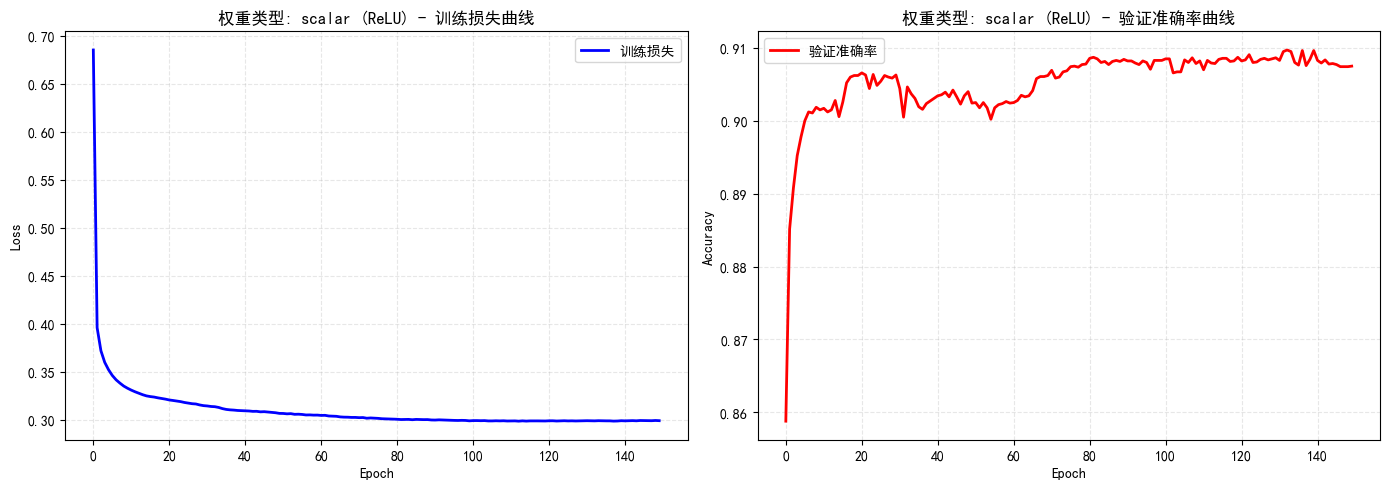


实验: 权重类型 = diagonal (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=diagonal
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 对角权重 (8个权重参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=0.7637, 验证准确率=0.8292
Epoch  10/150: 训练损失=0.3531, 验证准确率=0.8897
Epoch  20/150: 训练损失=0.3287, 验证准确率=0.9028
Epoch  30/150: 训练损失=0.3128, 验证准确率=0.9022
Epoch  40/150: 训练损失=0.3063, 验证准确率=0.9072
Epoch  50/150: 训练损失=0.3055, 验证准确率=0.9078
Epoch  60/150: 训练损失=0.3052, 验证准确率=0.9119
Epoch  70/150: 训练损失=0.3035, 验证准确率=0.9137
Epoch  80/150: 训练损失=0.3008, 验证准确率=0.9134
Epoch  90/150: 训练损失=0.2967, 验证准确率=0.9115
Epoch 100/150: 训练损失=0.2947, 验证准确率=0.9109
Epoch 110/150: 训练损失=0.2920, 验证准确率=0.9116
Epoch 120/150: 训练损失=0.2912, 验证准确率=0.9102
Epoch 130/150: 训练损失=0.2911, 验证准确率=0.9074
Epoch 140/150: 训练损失=0.2910, 验证准确率=0.9071
Epoch 150/150: 训练损失=0.2906, 验证准确率=0.9084

训练完成! 最佳验证准确率: 0.9139


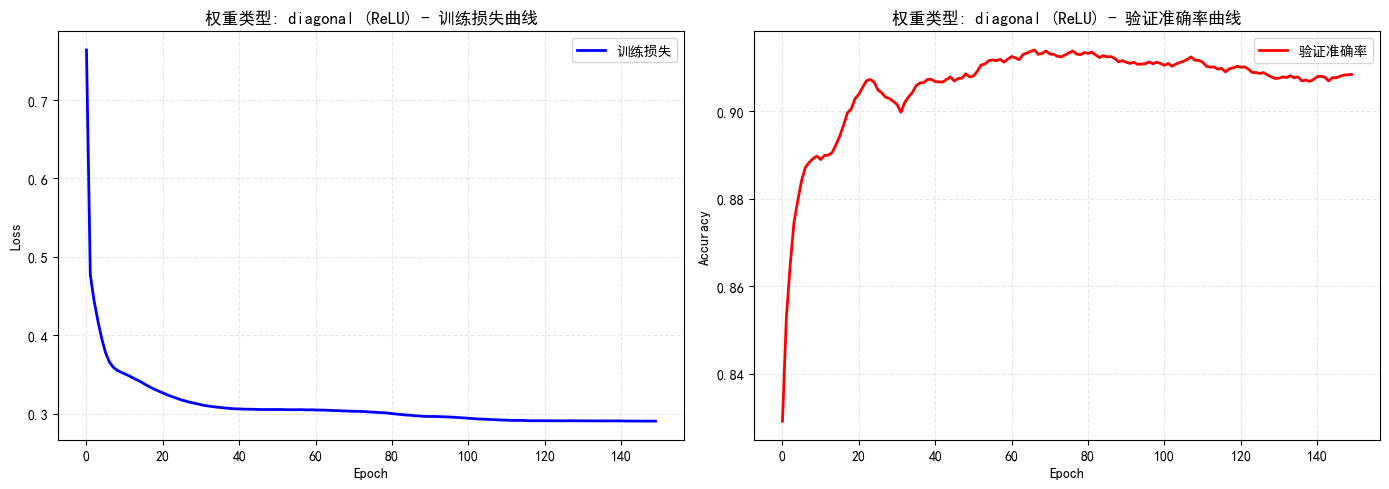


实验: 权重类型 = full (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=full
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 全连接权重 (72个参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=0.8844, 验证准确率=0.8170
Epoch  10/150: 训练损失=0.3143, 验证准确率=0.9043
Epoch  20/150: 训练损失=0.2988, 验证准确率=0.9114
Epoch  30/150: 训练损失=0.2931, 验证准确率=0.9094
Epoch  40/150: 训练损失=0.2889, 验证准确率=0.9119
Epoch  50/150: 训练损失=0.2861, 验证准确率=0.9129
Epoch  60/150: 训练损失=0.2844, 验证准确率=0.9142
Epoch  70/150: 训练损失=0.2825, 验证准确率=0.9138
Epoch  80/150: 训练损失=0.2819, 验证准确率=0.9137
Epoch  90/150: 训练损失=0.2818, 验证准确率=0.9141
Epoch 100/150: 训练损失=0.2819, 验证准确率=0.9135
Epoch 110/150: 训练损失=0.2827, 验证准确率=0.9148
Epoch 120/150: 训练损失=0.2824, 验证准确率=0.9147
Epoch 130/150: 训练损失=0.2809, 验证准确率=0.9162
Epoch 140/150: 训练损失=0.2778, 验证准确率=0.9185
Epoch 150/150: 训练损失=0.2771, 验证准确率=0.9177

训练完成! 最佳验证准确率: 0.9185


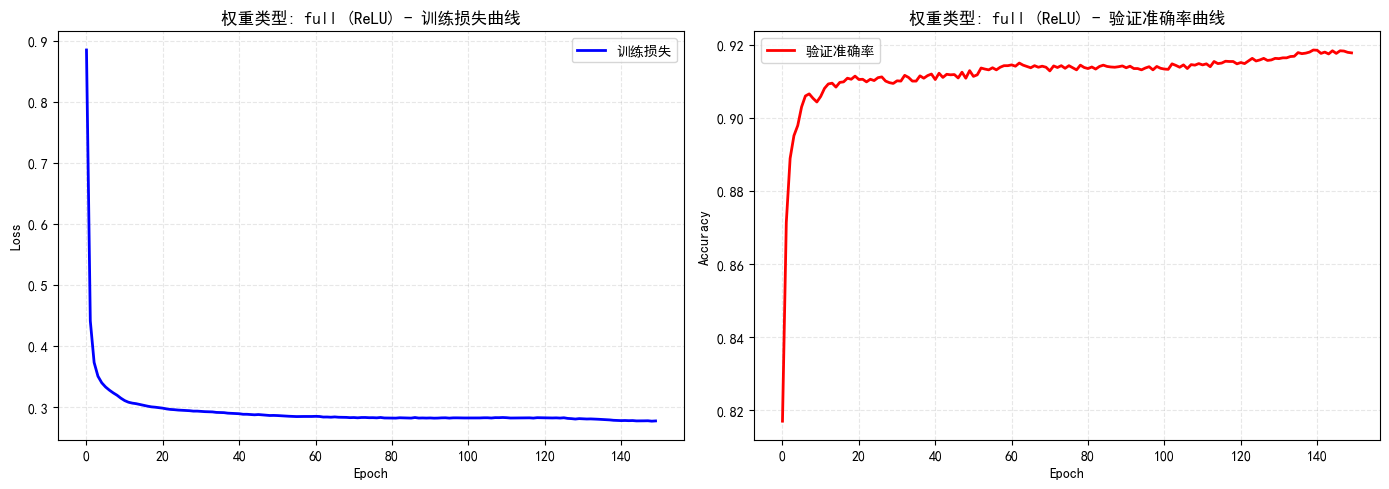


实验结果汇总 (自编码器降维 + 测量后权重 + ReLU)
scalar    : 最佳验证准确率 = 0.9097
diagonal  : 最佳验证准确率 = 0.9139
full      : 最佳验证准确率 = 0.9185

所有结果已保存到 autoencoder_weight_relu_results.npz


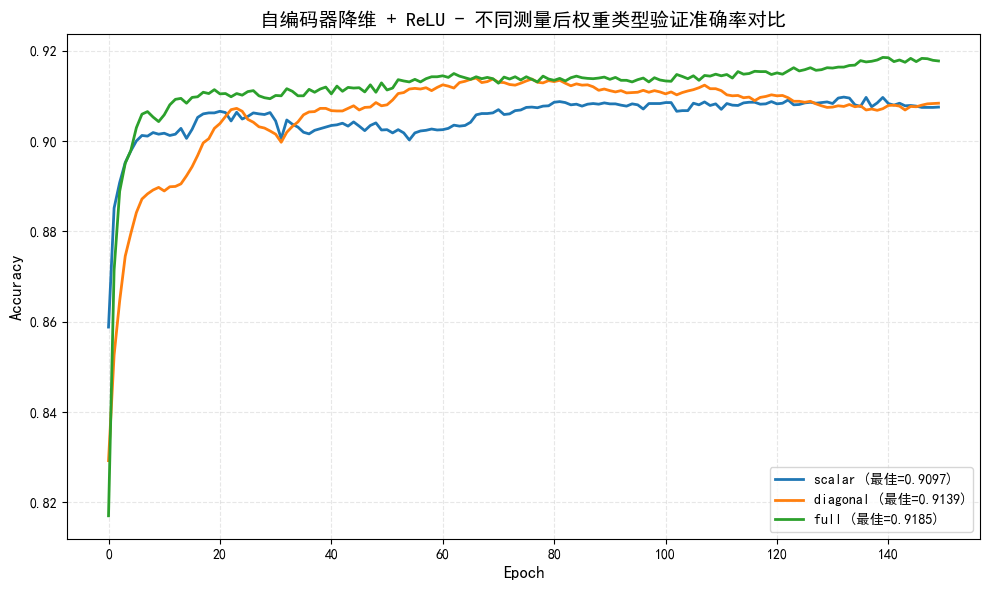

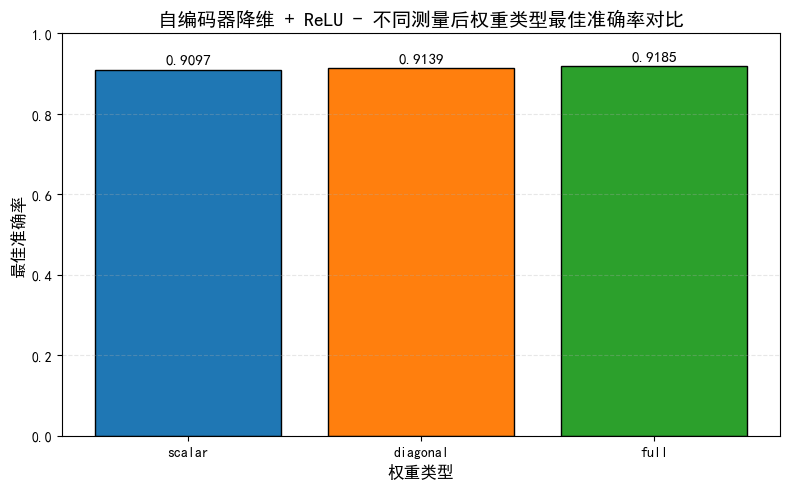

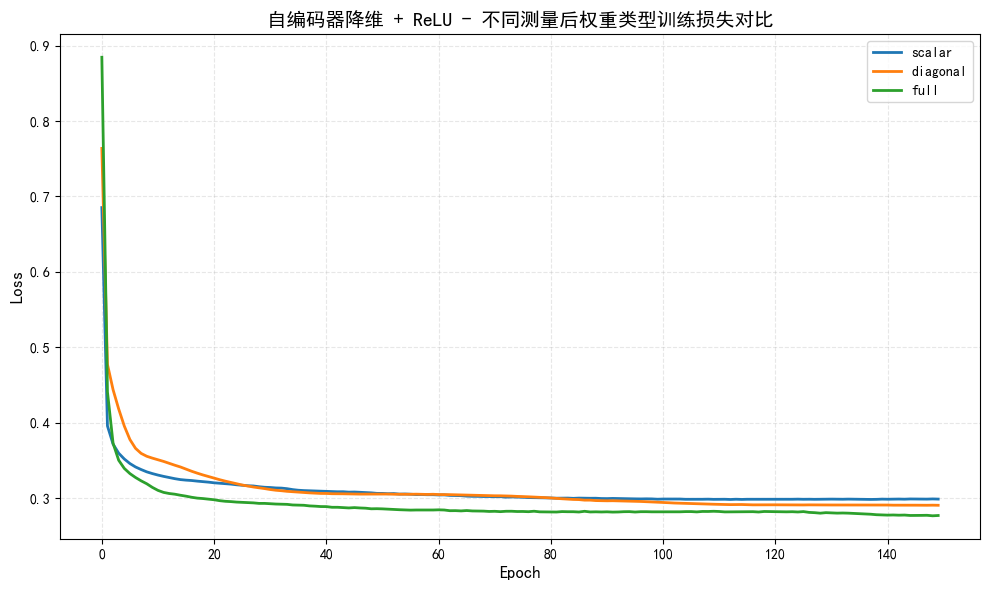

In [6]:
# 第六部分：主程序 - 自编码器降维 + 测量后权重实验（带 ReLU 激活）
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("自编码器降维 + 测量后可学习权重(带ReLU)实验 - 固定Ansatz: sequential_su4, 层数=2")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. 自编码器降维预处理（与实验三基线一致）
    print("\n步骤3：自编码器降维预处理")
    train_dataset, final_scaler, encoder, scaler_for_ae = preprocess_data_autoencoder(
        train_images, train_labels, is_train=True
    )
    test_dataset, _, _, _ = preprocess_data_autoencoder(
        test_images, test_labels, encoder=encoder,
        scaler_for_ae=scaler_for_ae, final_scaler=final_scaler, is_train=False
    )
    print("自编码器降维和归一化完成，数据集已准备好。")

    # 4. 遍历三种权重类型进行实验
    all_results = {}  # 键为 weight_type

    for weight_type in WEIGHT_TYPES:
        print(f"\n{'='*60}")
        print(f"实验: 权重类型 = {weight_type} (含 ReLU 激活)")
        print(f"{'='*60}")

        # 训练模型
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            weight_type=weight_type,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[weight_type] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制单个实验的曲线
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].plot(train_losses, 'b-', linewidth=2, label='训练损失')
        axes[0].set_title(f'权重类型: {weight_type} (ReLU) - 训练损失曲线', fontsize=12)
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Loss')
        axes[0].grid(True, alpha=0.3, linestyle='--')
        axes[0].legend()

        axes[1].plot(val_accuracies, 'r-', linewidth=2, label='验证准确率')
        axes[1].set_title(f'权重类型: {weight_type} (ReLU) - 验证准确率曲线', fontsize=12)
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Accuracy')
        axes[1].grid(True, alpha=0.3, linestyle='--')
        axes[1].legend()
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果
    print("\n" + "=" * 60)
    print("实验结果汇总 (自编码器降维 + 测量后权重 + ReLU)")
    print("=" * 60)
    for weight_type, res in all_results.items():
        print(f"{weight_type:10s}: 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存所有结果（ReLU 版本，新文件名）
    np.savez('autoencoder_weight_relu_results.npz',
             weight_types=WEIGHT_TYPES,
             train_losses={wt: all_results[wt]['train_losses'] for wt in WEIGHT_TYPES},
             val_accuracies={wt: all_results[wt]['val_accuracies'] for wt in WEIGHT_TYPES},
             best_val_accs={wt: all_results[wt]['best_val_acc'] for wt in WEIGHT_TYPES})
    print("\n所有结果已保存到 autoencoder_weight_relu_results.npz")

    # 8. 绘制所有权重类型的对比曲线（综合）
    plt.figure(figsize=(10, 6))
    for weight_type in WEIGHT_TYPES:
        plt.plot(all_results[weight_type]['val_accuracies'],
                 label=f'{weight_type} (最佳={all_results[weight_type]["best_val_acc"]:.4f})',
                 linewidth=2)
    plt.title('自编码器降维 + ReLU - 不同测量后权重类型验证准确率对比', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

    # 9. 绘制最佳准确率柱状图
    plt.figure(figsize=(8, 5))
    best_accs = [all_results[wt]['best_val_acc'] for wt in WEIGHT_TYPES]
    bars = plt.bar(WEIGHT_TYPES, best_accs, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
    plt.title('自编码器降维 + ReLU - 不同测量后权重类型最佳准确率对比', fontsize=14)
    plt.xlabel('权重类型', fontsize=12)
    plt.ylabel('最佳准确率', fontsize=12)
    plt.ylim(0, 1.0)
    for bar, acc in zip(bars, best_accs):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{acc:.4f}', ha='center', va='bottom', fontsize=11)
    plt.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

    # 10. 绘制训练损失对比曲线
    plt.figure(figsize=(10, 6))
    for weight_type in WEIGHT_TYPES:
        plt.plot(all_results[weight_type]['train_losses'],
                 label=f'{weight_type}', linewidth=2)
    plt.title('自编码器降维 + ReLU - 不同测量后权重类型训练损失对比', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()
